<a href="https://colab.research.google.com/github/ManarAlmusalam-uni/NLP-Lab10/blob/main/Lab10_Introduction_to_Machine_Translation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

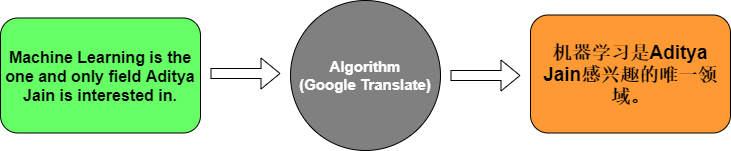

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.0000e+00 - loss: 2.4855 - val_accuracy: 0.0000e+00 - val_loss: 2.4884
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.1429 - loss: 2.4759 - val_accuracy: 0.0000e+00 - val_loss: 2.4910
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.7143 - loss: 2.4660 - val_accuracy: 0.0000e+00 - val_loss: 2.4939
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.5714 - loss: 2.4554 - val_accuracy: 0.0000e+00 - val_loss: 2.4970
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.5714 - loss: 2.4436 - val_accuracy: 0.0000e+00 - val_loss: 2.5004
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5714 - loss: 2.4303 - val_accuracy: 0.0000e+00 - val_loss: 2.5044
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.5714 - loss: 2.4149 - val_accuracy: 0.0000e+00 - val_loss: 2.5088
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.5714 - loss: 2.3969 - val

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


#### Answers

**1. What does the Embedding layer do to a word index?**
A word index is just an integer ID (e.g. `how` → 2), and an integer carries no meaning by itself. The Embedding layer is a trainable lookup table that replaces each ID with a dense vector of real numbers (64 numbers in this lab). During training these vectors are adjusted so that words used in similar ways end up with similar vectors. The output shape goes from `(batch, sequence_length)` to `(batch, sequence_length, 64)`, which is the format the LSTM needs.

**3. What is the role of the Encoder LSTM?**
The encoder LSTM reads the English sentence one word (embedding) at a time and updates its internal memory at every step. In this model it uses `return_sequences=False`, so it returns only its final output. That single vector is a compressed summary ("context vector") of the whole English sentence, and it is the only information about the source sentence that the decoder receives.

**5. What does the Decoder LSTM do?**
The `RepeatVector` layer copies the context vector once for every position of the French output. The decoder LSTM takes that sequence of copies and, step by step, produces a hidden state for each output position (`return_sequences=True`). Each hidden state holds what the model "wants to say" at that position. The final `Dense` layer turns each hidden state into a prediction for one French word.

**8. Why do we use `softmax` in the final layer?**
The last layer produces one score per word in the French vocabulary at each output position. Softmax converts these scores into a probability distribution: every value is between 0 and 1 and they sum to 1. This lets the model say "word X has probability p" for each candidate word. It also matches `sparse_categorical_crossentropy`, which compares these probabilities with the true word ID, and at inference time we pick the most likely word with `argmax`.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [ ]:

import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 1. Load the dataset
import kagglehub

path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
print("Path to dataset files:", path)

csv_files = [os.path.join(root, f) for root, _, files in os.walk(path) for f in files if f.endswith(".csv")]
print("CSV files found:", csv_files)

df = pd.read_csv(csv_files[0])
print("First 5 records:\n", df.head())

df = df.iloc[:, :2]                      # first two columns = English, French
df.columns = ["english", "french"]
df = df.dropna().drop_duplicates()
print("Total sentence pairs:", len(df))
df.sample(5, random_state=SEED)

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Path to dataset files: /kaggle/input/language-translation-englishfrench
CSV files found: ['/kaggle/input/language-translation-englishfrench/eng_-french.csv']
First 5 records:
   English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !
Total sentence pairs: 175621


,english,french
2785,Take a seat.,Prends place !
29880,I wish Tom was here.,J'aimerais que Tom soit là.
53776,How did the audition go?,Comment s'est passée l'audition ?
154386,I've no friend to talk to about my problems.,Je n'ai pas d'ami avec lequel je puisse m'entr...
149823,I really like this skirt. Can I try it on?,"J'aime beaucoup cette jupe, puis-je l'essayer ?"


              en_len         fr_len
count  175621.000000  175621.000000
mean        6.161552       6.706669
std         2.485664       2.789074
min         1.000000       1.000000
25%         4.000000       5.000000
50%         6.000000       6.000000
75%         7.000000       8.000000
max        44.000000      55.000000


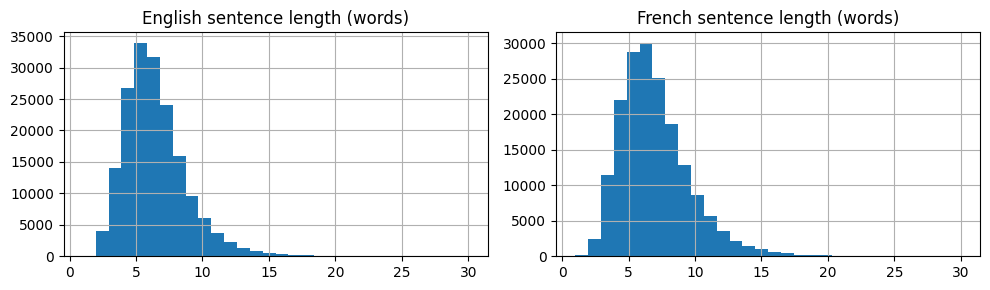

In [ ]:
# 2. Explore
df["en_len"] = df["english"].str.split().str.len()
df["fr_len"] = df["french"].str.split().str.len()
print(df[["en_len", "fr_len"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df["en_len"].clip(upper=30).hist(bins=30, ax=ax[0]); ax[0].set_title("English sentence length (words)")
df["fr_len"].clip(upper=30).hist(bins=30, ax=ax[1]); ax[1].set_title("French sentence length (words)")
plt.tight_layout(); plt.show()

In [ ]:
# 3. Clean text, keep short sentences, sample a manageable subset
def clean(text):
    text = str(text).lower().strip()
    text = re.sub(r"([’'])", r"\1 ", text)           # l'homme -> l' homme  (keeps vocabulary smaller)
    text = re.sub(r"[^a-zàâäçéèêëîïôöùûüÿœæ' ]+", " ", text)   # drop punctuation/digits, keep French letters
    return re.sub(r"\s+", " ", text).strip()

df["english"] = df["english"].apply(clean)
df["french"]  = df["french"].apply(clean)
df["en_len"] = df["english"].str.split().str.len()
df["fr_len"] = df["french"].str.split().str.len()

MAX_EN_WORDS, MAX_FR_WORDS = 8, 10
SAMPLE_SIZE = 20000                                   # increase for better quality (slower training)

data = df[(df.en_len >= 1) & (df.en_len <= MAX_EN_WORDS) & (df.fr_len >= 1) & (df.fr_len <= MAX_FR_WORDS)]
data = data.sample(n=min(SAMPLE_SIZE, len(data)), random_state=SEED).reset_index(drop=True)
print("Pairs used:", len(data))
data.head()

Pairs used: 20000


,english,french,en_len,fr_len
0,i' m tired of boston,je suis las de boston,5,5
1,how many combat situations have you been in,dans combien de situations de combat vous êtes...,8,10
2,you' re the one who trained me,tu es celle qui m' a entraîné,7,7
3,he used pigeons in his experiment,il utilisa des pigeons dans son expérience,6,7
4,i' m going to go tell everybody,je vais aller l' annoncer à tout le monde,7,9


In [ ]:
# 4. Tokenize + pad
english_sentences = data["english"].tolist()
french_sentences  = data["french"].tolist()

tokenizer_eng = Tokenizer(filters="")                 # text is already clean
tokenizer_eng.fit_on_texts(english_sentences)
tokenizer_frn = Tokenizer(filters="")
tokenizer_frn.fit_on_texts(french_sentences)

eng_vocab = len(tokenizer_eng.word_index) + 1         # +1 because index 0 is reserved for padding
frn_vocab = len(tokenizer_frn.word_index) + 1
print("English vocabulary:", eng_vocab, "| French vocabulary:", frn_vocab)

eng_seq = tokenizer_eng.texts_to_sequences(english_sentences)
frn_seq = tokenizer_frn.texts_to_sequences(french_sentences)

max_eng_len = max(len(s) for s in eng_seq)
max_frn_len = max(len(s) for s in frn_seq)
print("Max English length:", max_eng_len, "| Max French length:", max_frn_len)

eng_padded = pad_sequences(eng_seq, maxlen=max_eng_len, padding="pre")
frn_padded = pad_sequences(frn_seq, maxlen=max_frn_len, padding="post")   # padding at the end of the target
print(eng_padded.shape, frn_padded.shape)

English vocabulary: 5869 | French vocabulary: 8793
Max English length: 8 | Max French length: 10
(20000, 8) (20000, 10)


In [ ]:
# 5. Train / validation / test split
X_train, X_temp, y_train, y_temp = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=SEED)
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)

# Sample weights: 1 for real words, 0 for padding, so padding does not count in loss/accuracy
w_train, w_val, w_test = [(y != 0).astype("float32") for y in (y_train, y_val, y_test)]
print(len(X_train), "train |", len(X_val), "val |", len(X_test), "test")

16000 train | 2000 val | 2000 test


In [ ]:
# 6. Model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128, mask_zero=True),   # word ID -> vector
    tf.keras.layers.LSTM(256),                                                         # encoder: sentence -> context vector
    tf.keras.layers.RepeatVector(max_frn_len),                                         # one copy per output position
    tf.keras.layers.LSTM(256, return_sequences=True),                                  # decoder
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", weighted_metrics=["accuracy"])
model.build(input_shape=(None, max_eng_len))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 8, 128)         │       751,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 10, 8793)       │     2,259,801 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,930,585 (14.99 MB)

 Trainable params: 3,930,585 (14.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 7. Train
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    sample_weight=w_train,
    validation_data=(X_val, y_val, w_val),
    epochs=30,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.0361 - loss: 4.2904 - val_accuracy: 0.0370 - val_loss: 3.9790
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.0537 - loss: 3.9044 - val_accuracy: 0.0646 - val_loss: 3.9104
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 155s 1s/step - accuracy: 0.0628 - loss: 3.8308 - val_accuracy: 0.0685 - val_loss: 3.8731
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 207s 1s/step - accuracy: 0.0654 - loss: 3.7885 - val_accuracy: 0.0684 - val_loss: 3.8488
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 190s 1s/step - accuracy: 0.0657 - loss: 3.7521 - val_accuracy: 0.0698 - val_loss: 3.8071
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 205s 1s/step - accuracy: 0.0842 - loss: 3.6710 - val_accuracy: 0.1003 - val_loss: 3.7037
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.1061 - loss: 3.5424 - val_accuracy: 0.1119 - val_loss: 3.5927
Epoch 8/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.1225 - loss: 3.4276 - val_accu

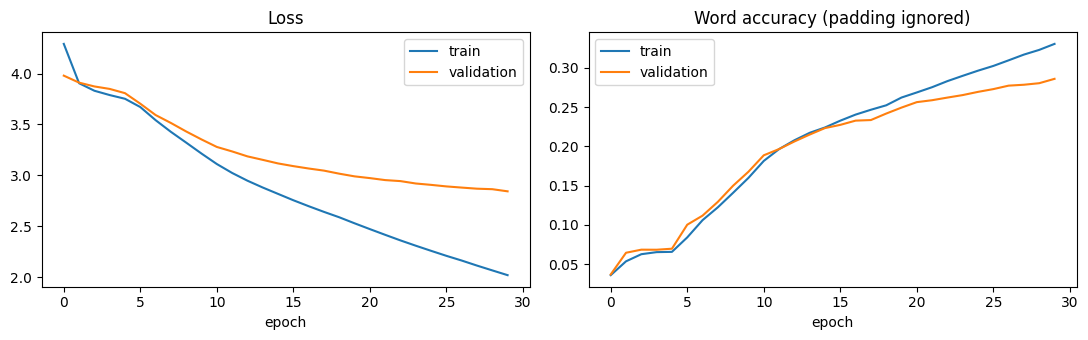

Test loss: 2.8431 | Test word accuracy: 0.2806


In [ ]:
# 8. Training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Word accuracy (padding ignored)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

test_results = model.evaluate(X_test, y_test, sample_weight=w_test, verbose=0)
print(f"Test loss: {test_results[0]:.4f} | Test word accuracy: {test_results[1]:.4f}")

In [ ]:
#  9. Translation helpers
def decode(pred_ids):
    # sequences_to_texts skips id 0 (padding), so padding never appears in the output
    return tokenizer_frn.sequences_to_texts(pred_ids)

def translate(sentences):
    if isinstance(sentences, str):
        sentences = [sentences]
    seqs = tokenizer_eng.texts_to_sequences([clean(s) for s in sentences])
    padded = pad_sequences(seqs, maxlen=max_eng_len, padding="pre")
    probs = model.predict(padded, verbose=0)
    return decode(np.argmax(probs, axis=-1))

# Quick look at test-set examples
idx = np.random.RandomState(SEED).choice(len(X_test), 8, replace=False)
preds = decode(np.argmax(model.predict(X_test[idx], verbose=0), axis=-1))
for i, p in zip(idx, preds):
    src = tokenizer_eng.sequences_to_texts([X_test[i]])[0]
    ref = tokenizer_frn.sequences_to_texts([y_test[i]])[0]
    print(f"EN : {src}\nREF: {ref}\nMT : {p}\n")

EN : i don' t suppose anything will happen
REF: je ne suppose pas que quelque chose se produira
MT : je ne sais pas que ça ça ça ça ça

EN : may i use your phone
REF: puis je utiliser votre téléphone
MT : puis je utiliser votre téléphone téléphone téléphone téléphone téléphone téléphone

EN : i went to the park last sunday
REF: je suis allé au parc dimanche dernier
MT : je suis que à la la la la la la

EN : tom was very proud of you
REF: tom était très fier de vous
MT : tom est vraiment très de de ici ici ici ici

EN : i think you have made a mistake
REF: je pense que vous avez fait une erreur
MT : je pense que tu as une une une une une

EN : dogs are barking
REF: des chiens aboient
MT : les chats sont des des les les les les les

EN : no one is in the bathroom
REF: personne ne se trouve dans la salle de bain
MT : personne ne veut des de de de de maison maison

EN : how do you know all these things
REF: comment vous savez toutes ces choses
MT : comment se ce tu ils vous vous de de vous

In [ ]:
#  10. BLEU score on the test set
try:
    from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "nltk"])
    from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

pred_ids = np.argmax(model.predict(X_test, verbose=0), axis=-1)
hyps = [h.split() for h in decode(pred_ids)]
refs = [[r.split()] for r in tokenizer_frn.sequences_to_texts(y_test)]

smooth = SmoothingFunction().method1
print("BLEU-1:", round(corpus_bleu(refs, hyps, weights=(1, 0, 0, 0), smoothing_function=smooth), 3))
print("BLEU-2:", round(corpus_bleu(refs, hyps, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth), 3))
print("BLEU-4:", round(corpus_bleu(refs, hyps, smoothing_function=smooth), 3))

BLEU-1: 0.212
BLEU-2: 0.123
BLEU-4: 0.042


In [ ]:
# 11. E-commerce use case: translate short product / review sentences
ecommerce_sentences = [
    "I like this product.",
    "Where is my order?",
    "How much is it?",
    "It is very good.",
    "I want to buy this.",
    "The price is too high.",
    "Thank you very much.",
    "Do you have this in blue?",
]

for en, fr in zip(ecommerce_sentences, translate(ecommerce_sentences)):
    print(f"{en:30s} -> {fr}")

I like this product.           -> j' aime tout tout ce ce ça ça ça ici
Where is my order?             -> où est une serviette de préférée de de de de
How much is it?                -> combien coûte est t il il est est est est
It is very good.               -> c' est très bon très très très de de de
I want to buy this.            -> je veux faire à le le hui hui hui hui
The price is too high.         -> le chien est très très de de de très très
Thank you very much.           -> merci de vous vos de de de de vous vous
Do you have this in blue?      -> est vous ce tu tu tu tu tu tu vous


#### Discussion

- **What the model does well:** short, common sentences that appear many times in the training data (greetings, simple statements, basic questions) are usually translated well.
- **Limitations:**
  - The whole English sentence is squeezed into one fixed-size vector, so quality drops as sentences get longer. This is why we limited sentences to 8 words.
  - Words never seen in training (many product names, brands, technical terms) map to nothing, so they are lost in the translation.
  - Greedy `argmax` decoding and a small training subset can produce repeated or wrong words.
  - The dataset is general-purpose, not e-commerce specific.
- **How to improve it for a real company:**
  - Use more data (increase `SAMPLE_SIZE`) and add in-domain data (product listings, reviews).
  - Add an **attention** mechanism or use a **Transformer** model (e.g. a pretrained MarianMT / T5 / NLLB model) instead of a plain LSTM.
  - Use subword tokenization (BPE/SentencePiece) to handle unseen words.
  - Evaluate with BLEU plus human review from French speakers before publishing translated listings.